Prueba ganador y challenger 

In [1]:
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score, balanced_accuracy_score, confusion_matrix
from src.datos import cargar_obt, metadatos_datos
from src import pipeline as P

df = P.agregar_features(cargar_obt())
train, test = P.dividir_train_test(df)
X_tr, y_tr = P.preparar_X_y(train)
X_te, y_te = P.preparar_X_y(test)
META = metadatos_datos(df)
mlflow = P.configurar_mlflow()

# Los 3 modelos ajustados (corridas padre del tuning), ordenados por ROC-AUC de CV
exp = mlflow.get_experiment_by_name("merma-cerveza")
padres = mlflow.search_runs([exp.experiment_id], filter_string="tags.tipo = 'padre'",
                            order_by=["metrics.cv_roc_auc_media DESC"])
cols = ["tags.mlflow.runName", "run_id", "metrics.cv_roc_auc_media", "metrics.cv_roc_auc_std",
        "metrics.brecha", "metrics.cv_costo_media", "metrics.segundos_entrenamiento"]
display(padres[cols].round(3))

ganador, segundo = padres.iloc[0], padres.iloc[1]
dif = ganador["metrics.cv_roc_auc_media"] - segundo["metrics.cv_roc_auc_media"]
std_max = max(ganador["metrics.cv_roc_auc_std"], segundo["metrics.cv_roc_auc_std"])
print(f"Ganador por CV: {ganador['tags.mlflow.runName']} | Segundo: {segundo['tags.mlflow.runName']}")
print(f"Diferencia de ROC-AUC: {dif:.3f} | desviación entre pliegues: {std_max:.3f} | ¿la supera? {dif > std_max}")

,tags.mlflow.runName,run_id,metrics.cv_roc_auc_media,metrics.cv_roc_auc_std,metrics.brecha,metrics.cv_costo_media,metrics.segundos_entrenamiento
0,tuning_mlp,98541bb7d28e4bf9bec8cf445b0e3e7f,0.664,0.143,0.037,32.495,0.483
1,tuning_logistica,50220710ff9b468099abd9ca6cd218c0,0.635,0.123,-0.038,30.734,0.019
2,tuning_random_forest,51e12d31977143fd89642a4298a02cb6,0.629,0.143,0.359,23.060,0.298


Ganador por CV: tuning_mlp | Segundo: tuning_logistica
Diferencia de ROC-AUC: 0.028 | desviación entre pliegues: 0.143 | ¿la supera? False


Umbral segun el costo 

mlp: umbral óptimo 0.05 → costo CV $12.44 por lote
logistica: umbral óptimo 0.05 → costo CV $12.44 por lote


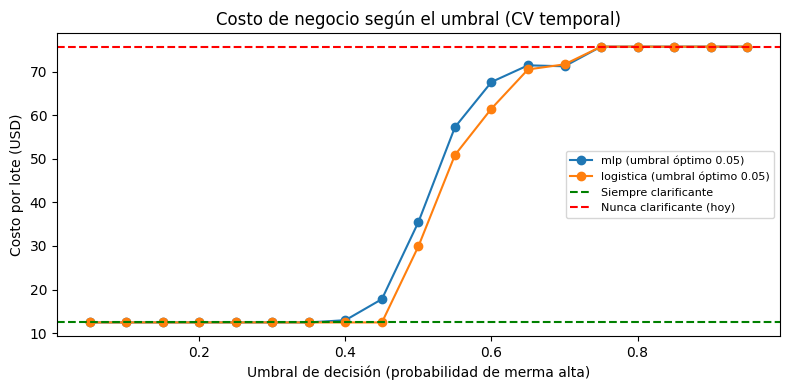

In [2]:
from sklearn.base import clone

# Los dos modelos ajustados, tal como quedaron guardados en MLflow
modelos = {}
for fila in [ganador, segundo]:
    nombre = fila["tags.mlflow.runName"].replace("tuning_", "")
    modelos[nombre] = {"run_id": fila["run_id"],
                       "pipe": mlflow.sklearn.load_model(f"runs:/{fila['run_id']}/modelo")}

def costo_real(lotes, pred):
    """Costo promedio por lote (USD) con el precio de CADA estilo y el volumen de CADA lote."""
    costo_fn, costo_fp = P.costos_por_lote(lotes)
    y = lotes["merma_alta"].values
    return float((((pred == 0) & (y == 1)) * costo_fn.values + ((pred == 1) & (y == 0)) * costo_fp.values).sum() / len(y))

UMBRALES = np.round(np.arange(0.05, 0.96, 0.05), 2)
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, m in modelos.items():
    probs, idx = [], []
    for i_tr, i_va in P.esquema_cv().split(train):                     # predicciones fuera de pliegue
        modelo_k = clone(m["pipe"]).fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
        probs.append(modelo_k.predict_proba(X_tr.iloc[i_va])[:, 1]); idx.append(i_va)
    probs, idx = np.concatenate(probs), np.concatenate(idx)
    lotes_val = train.iloc[idx]
    costos = [costo_real(lotes_val, (probs >= u).astype(int)) for u in UMBRALES]
    m["umbral"] = float(UMBRALES[int(np.argmin(costos))])
    ax.plot(UMBRALES, costos, marker="o", label=f"{nombre} (umbral óptimo {m['umbral']})")
    print(f"{nombre}: umbral óptimo {m['umbral']} → costo CV ${min(costos):.2f} por lote")

ax.axhline(costo_real(lotes_val, np.ones(len(lotes_val), int)), ls="--", color="green", label="Siempre clarificante")
ax.axhline(costo_real(lotes_val, np.zeros(len(lotes_val), int)), ls="--", color="red", label="Nunca clarificante (hoy)")
ax.set_xlabel("Umbral de decisión (probabilidad de merma alta)"); ax.set_ylabel("Costo por lote (USD)")
ax.set_title("Costo de negocio según el umbral (CV temporal)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../docs/figs/08_umbral_costo.png", dpi=150); plt.show()

Evaluacion de modelos 

In [3]:
filas = []
for nombre, m in modelos.items():
    pipe = m["pipe"]
    t0 = time.time(); prob_te = pipe.predict_proba(X_te)[:, 1]; seg_inf = (time.time() - t0) / len(X_te) * 1000
    for etiqueta, u in [("umbral 0.5", 0.5), (f"umbral costo {m['umbral']}", m["umbral"])]:
        pred = (prob_te >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
        filas.append({"modelo": nombre, "umbral": etiqueta,
                      "roc_auc_prueba": roc_auc_score(y_te, prob_te),
                      "f1": f1_score(y_te, pred), "balanced_acc": balanced_accuracy_score(y_te, pred),
                      "costo_por_lote_usd": costo_real(test, pred),
                      "VP": tp, "FN": fn, "FP": fp, "VN": tn, "ms_por_lote": seg_inf})
    m["prob_te"] = prob_te

for nombre, pred in [("siempre clarificante", np.ones(len(test), int)), ("nunca clarificante (hoy)", np.zeros(len(test), int))]:
    filas.append({"modelo": nombre, "umbral": "-", "costo_por_lote_usd": costo_real(test, pred)})

tabla_prueba = pd.DataFrame(filas)
tabla_prueba.to_csv("../docs/resultados_prueba.csv", index=False)
tabla_prueba.round(3)

,modelo,umbral,roc_auc_prueba,f1,balanced_acc,costo_por_lote_usd,VP,FN,FP,VN,ms_por_lote
0,mlp,umbral 0.5,0.500,0.725,0.403,27.372,25.0,11.0,8.0,1.0,0.208
1,mlp,umbral costo 0.05,0.500,0.889,0.500,5.848,36.0,0.0,9.0,0.0,0.208
2,logistica,umbral 0.5,0.525,0.889,0.500,5.848,36.0,0.0,9.0,0.0,0.611
3,logistica,umbral costo 0.05,0.525,0.889,0.500,5.848,36.0,0.0,9.0,0.0,0.611
4,siempre clarificante,-,NaN,NaN,NaN,5.848,NaN,NaN,NaN,NaN,NaN
5,nunca clarificante (hoy),-,NaN,NaN,NaN,94.933,NaN,NaN,NaN,NaN,NaN


Modelo champion: Logistica 
Modelo challenger: MLP
Conclusión de negocio: con el umbral de costo, el champion recomienda clarificante en todos los lotes, y eso ahorra unos $89 por lote frente a hoy ($94.93 → $5.85).

Registro del modelo 

In [4]:
from mlflow import MlflowClient
from mlflow.models import infer_signature

NOMBRE_REGISTRO = "merma-cerveza-modelo"
FAMILIA = {"logistica": "lineal_regularizado", "mlp": "red_neuronal"}
ROLES = [("champion", "logistica"), ("challenger", "mlp")]
client = MlflowClient()

for rol, nombre in ROLES:
    m = modelos[nombre]; pipe = m["pipe"]; u = m["umbral"]
    pred = (m["prob_te"] >= u).astype(int)
    metricas_finales = {
        "roc_auc_prueba": roc_auc_score(y_te, m["prob_te"]),
        "f1_prueba": f1_score(y_te, pred),
        "balanced_acc_prueba": balanced_accuracy_score(y_te, pred),
        "costo_prueba_usd": costo_real(test, pred),
        "costo_siempre_clarificante_usd": costo_real(test, np.ones(len(test), int)),
        "costo_nunca_clarificante_usd": costo_real(test, np.zeros(len(test), int)),
    }
    with mlflow.start_run(run_name=f"final_{nombre}") as run:
        mlflow.log_params({"modelo": nombre, "umbral_decision": u, "run_tuning": m["run_id"],
                           "semilla": P.SEMILLA, **META})
        mlflow.log_metrics(metricas_finales)
        mlflow.set_tags({"fase": "final", "familia": FAMILIA[nombre], "rol": rol,
                         "commit_git": P.commit_git(), "esquema_cv": "TimeSeriesSplit(5)"})
        mlflow.sklearn.log_model(pipe, "modelo", signature=infer_signature(X_tr, pipe.predict_proba(X_tr)[:, 1]),
                                 input_example=X_tr.dropna().head(5))
    version = mlflow.register_model(f"runs:/{run.info.run_id}/modelo", NOMBRE_REGISTRO).version
    client.set_registered_model_alias(NOMBRE_REGISTRO, rol, version)
    client.set_model_version_tag(NOMBRE_REGISTRO, version, "umbral_decision", str(u))
    m.update({"run_final": run.info.run_id, "version": version, **metricas_finales})
    print(f"{rol:10s} → {nombre} | run_id {run.info.run_id} | versión {version} | "
          f"ROC-AUC prueba {metricas_finales['roc_auc_prueba']:.3f} | costo ${metricas_finales['costo_prueba_usd']:.2f}/lote")

2026/11/18 15:38:52 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:38:53 INFO mlflow.tracking._tracking_service.client: 🏃 View run final_logistica at: http://localhost:5050/#/experiments/1/runs/e96be0e9960b47bf836869be8483a3c8.
2026/11/18 15:38:53 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
Successfully registered model 'merma-cerveza-modelo'.
2026/11/18 15:38:53 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: merma-cerveza-modelo, version 1
Created version '1' of model 'merma-cerveza-modelo'.


champion   → logistica | run_id e96be0e9960b47bf836869be8483a3c8 | versión 1 | ROC-AUC prueba 0.525 | costo $5.85/lote


2026/11/18 15:38:58 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 15:38:58 INFO mlflow.tracking._tracking_service.client: 🏃 View run final_mlp at: http://localhost:5050/#/experiments/1/runs/a5f3cd32f86d4e35b797d49fe866b51f.
2026/11/18 15:38:58 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.
Registered model 'merma-cerveza-modelo' already exists. Creating a new version of this model...
2026/11/18 15:38:58 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: merma-cerveza-modelo, version 2
Created version '2' of model 'merma-cerveza-modelo'.


challenger → mlp | run_id a5f3cd32f86d4e35b797d49fe866b51f | versión 2 | ROC-AUC prueba 0.500 | costo $5.85/lote


Reproduccion de metrica desde el registro 

In [5]:
# Reproducción desde el Model Registry: no usa ninguna variable de celdas anteriores
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np
from sklearn.metrics import roc_auc_score
from src.datos import cargar_obt
from src import pipeline as P

mlflow = P.configurar_mlflow()
client = mlflow.MlflowClient()
NOMBRE = "merma-cerveza-modelo"

version = client.get_model_version_by_alias(NOMBRE, "champion")
modelo = mlflow.sklearn.load_model(f"models:/{NOMBRE}@champion")
umbral = float(version.tags["umbral_decision"])
registradas = client.get_run(version.run_id).data.metrics

_, test = P.dividir_train_test(P.agregar_features(cargar_obt()))
X_te, y_te = P.preparar_X_y(test)
prob = modelo.predict_proba(X_te)[:, 1]
pred = (prob >= umbral).astype(int)

costo_fn, costo_fp = P.costos_por_lote(test)
y = y_te.values
costo = float((((pred == 0) & (y == 1)) * costo_fn.values + ((pred == 1) & (y == 0)) * costo_fp.values).sum() / len(y))
roc = roc_auc_score(y_te, prob)

print(f"Champion: versión {version.version} | run_id {version.run_id} | umbral {umbral}")
print(f"ROC-AUC prueba  → reproducido {roc:.6f} | registrado {registradas['roc_auc_prueba']:.6f}")
print(f"Costo por lote  → reproducido ${costo:.4f} | registrado ${registradas['costo_prueba_usd']:.4f}")
assert np.isclose(roc, registradas["roc_auc_prueba"]) and np.isclose(costo, registradas["costo_prueba_usd"])
print("✔ La métrica registrada se reproduce exactamente")

Champion: versión 1 | run_id e96be0e9960b47bf836869be8483a3c8 | umbral 0.05
ROC-AUC prueba  → reproducido 0.524691 | registrado 0.524691
Costo por lote  → reproducido $5.8477 | registrado $5.8477
✔ La métrica registrada se reproduce exactamente


Exportar corridas csv 

In [6]:
# Exporta todas las corridas del experimento (el profesor no tiene acceso al servidor de MLflow)
from pathlib import Path

exp = mlflow.get_experiment_by_name("merma-cerveza")
corridas = mlflow.search_runs([exp.experiment_id], order_by=["start_time ASC"])
Path("../docs").mkdir(exist_ok=True)
corridas.to_csv("../docs/corridas.csv", index=False)

print(f"{len(corridas)} corridas exportadas a docs/corridas.csv")
print(corridas["tags.fase"].value_counts())

103 corridas exportadas a docs/corridas.csv
tags.fase
tuning       93
candidato     6
baseline      2
final         2
Name: count, dtype: int64
